# Perturb demo A: what does a CNN look at to find a Fourier decomposition?

In this demo we take a simple CNN through every step of Perturb, on a problem where we already know what the answer
should be.

**The problem.** A signal on $t \in [0, 1]$ (100 points) is the sum of $K$ sine waves with fixed frequencies $f_k$ and
fixed phases $\phi_k$, but unknown amplitudes $a_k \sim U(0, 1)$. On top of this is noise $\sigma(t)$ that grows along
$t$, standing in for the uncertainty of an observation:

$$x(t) = \sum_{k=1}^{K} a_k \sin(2\pi f_k t + \phi_k) + \varepsilon(t), \qquad \varepsilon(t) \sim \mathcal{N}(0, \sigma(t)^2).$$

**The black-box** $f$ is a 1D CNN trained to map $x$ to the $K$ amplitudes, with fresh noise drawn every epoch. It has
no dropout, so it gives the same answer every time it is called. We have pre-trained it for you, and the weights are
in `fourier/fourier_cnn.pt`. As every amplitude is carried by its own sine wave, we know what the network *should* be
looking at, so we can check that Perturb finds it.

**The method** has four steps:
1. `perturb.fit_kernel_width` finds the kernel width, i.e. how far apart two points can be and still move together.
2. `perturb.in_distribution_curve` finds how large a perturbation the network can still handle the same way it handles
   a small one.
3. `perturb.Perturber` calculates the response of $f$ to every perturbation of the sample, and from this the
   importance.
4. `perturb.plotting` draws the figures.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "fourier")                           # the demo problem; `pip install -e ..` installs perturb itself
sys.path.insert(0, str(Path("..", "src").resolve()))    # ... or use it straight from the repo
import perturb as pt
from perturb import plotting
from fourier import BASIS, FREQUENCIES, NAMES, SIGMA, T, contribution, forward, load_black_box, sample_amplitudes

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
rng = np.random.default_rng(2026)

## The sample

The sample we want to explain is a single noisy signal, $x^\star$. The top panel shows it against the noiseless
signal, and the bottom panel shows the same signal taken apart into its sine waves, each drawn at the height of its
frequency.

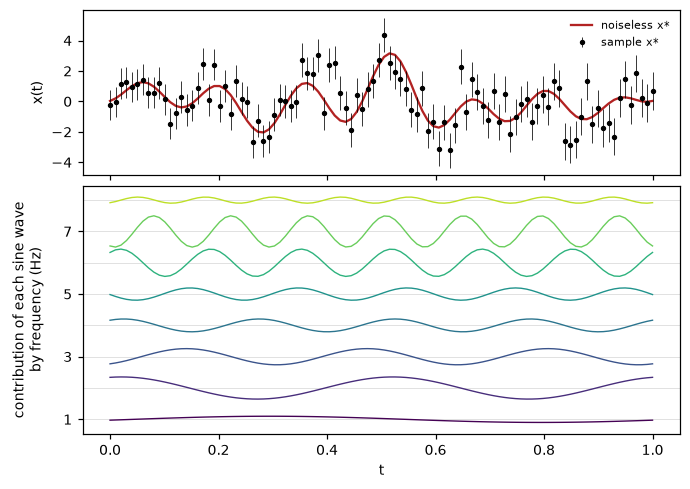

In [2]:
a_true = sample_amplitudes(1, rng)[0]

x_star_noiseless = forward(a_true)
x_star = x_star_noiseless + SIGMA * rng.standard_normal(len(T))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.5], hspace=0.05))
a1.plot(T, x_star_noiseless, "-", color="firebrick", label="noiseless x*")
a1.errorbar(T, x_star, yerr=SIGMA, fmt=".", color="k", ms=5, label="sample x*", elinewidth=0.5, capsize=0)
a1.set_ylabel("x(t)"); a1.legend(fontsize=7, frameon=False)

# the same signal taken apart into each sine wave a_k sin(2 pi f_k t + phi_k), drawn at the height of its frequency
spacing = 2 * np.abs(contribution(a_true)).max() / np.diff(FREQUENCIES).min()
for f_k, wave, colour in zip(FREQUENCIES, contribution(a_true), plt.cm.viridis(np.linspace(0, 0.9, len(FREQUENCIES)))):
    a2.axhline(f_k, color="0.85", lw=0.5)
    a2.plot(T, f_k + wave / spacing, color=colour, lw=0.9)
a2.set_yticks(FREQUENCIES[::2])
a2.set_xlabel("t"); a2.set_ylabel("contribution of each sine wave\nby frequency (Hz)")
fig.align_ylabels([a1, a2]);

## The black-box

`f` is the trained CNN wrapped up as a plain function, which takes an array of signals $(N, 100)$ and returns an array
of amplitudes $(N, K)$. This is all Perturb needs from a black-box. Below, the CNN's answer is put back through the
forward model and compared with the sample (left), and its amplitudes are compared with the true ones (right).

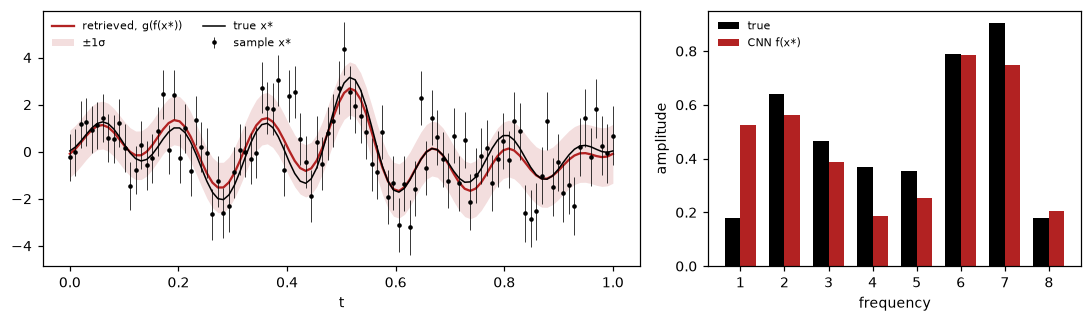

In [3]:
f = load_black_box()
a_cnn = f(x_star[None])[0]
x_retrieved = forward(a_cnn)   # the CNN's amplitudes put back through the forward model

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw=dict(width_ratios=[1.6, 1]))
a1.plot(T, x_retrieved, "-", color="firebrick", label="retrieved, g(f(x*))")
a1.fill_between(T, x_retrieved - SIGMA, x_retrieved + SIGMA, color="firebrick", lw=0, alpha=0.15, label="±1σ")
a1.errorbar(T, x_star, yerr=SIGMA, fmt=".", color="k", ms=4, label="sample x*", elinewidth=0.5, capsize=0)
a1.plot(T, x_star_noiseless, "-", color="k", lw=1, label="true x*")
a1.set_xlabel("t"); a1.legend(fontsize=7, frameon=False, ncol=2, loc='upper left')
w = 0.35
a2.bar(FREQUENCIES - w / 2, a_true, w, color="k", label="true")
a2.bar(FREQUENCIES + w / 2, a_cnn, w, color="firebrick", label="CNN f(x*)")
a2.set_xlabel("frequency"); a2.set_ylabel("amplitude"); a2.legend(fontsize=7, frameon=False)
fig.tight_layout()

## Step 1: the width of the Gaussian kernel

Rather than perturbing one point at a time, Gaussian perturbation moves a whole neighbourhood of points together, using
a window as wide as the scale over which real samples are correlated.

`fit_kernel_width` measures this scale from samples drawn from the prior. It calculates the Pearson correlation of
every pair of points, bins these by their separation, and fits a Gaussian to the result. Some data, such as
transmission spectra, need each sample to be min-max normalised first, as their overall depth varies far more than
their features do. These signals have no such offset, so we skip it here (`normalise=False`).

kernel FWHM = 0.0642 ± 0.0006 in t (6.4 points)


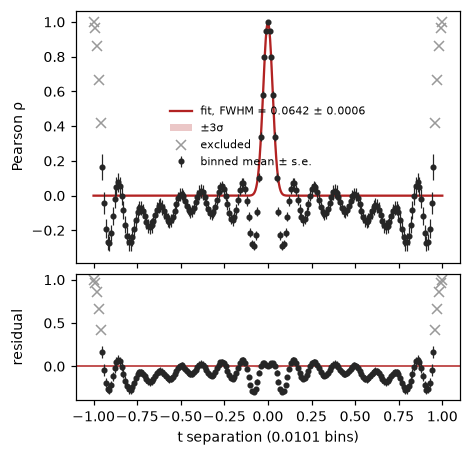

In [4]:
X_prior = forward(sample_amplitudes(5000, rng))      # noiseless samples from the prior

fit = pt.fit_kernel_width(X_prior, T, normalise=False)
FWHM = fit["fwhm"]
print(f"kernel FWHM = {FWHM:.4f} ± {fit['fwhm_err']:.4f} in t ({FWHM / np.diff(T)[0]:.1f} points)")
plotting.kernel_fit(fit, xlabel="t separation");

Neighbouring points are strongly correlated, and the correlation falls to zero within a few points, which is the core
that the Gaussian fits. The ripples further out are as a result of the sin waves. The correlation matrix
shows the same structure, as bands along the diagonal.

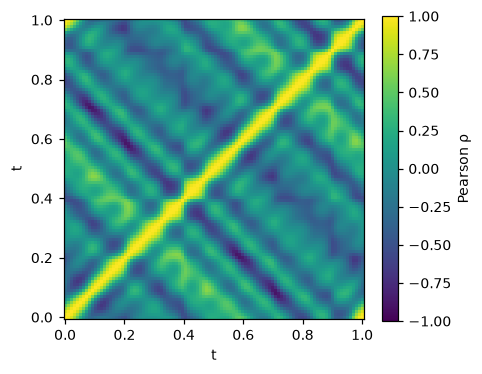

In [5]:
plotting.correlation_matrix(fit, xlabel="t");

## Step 2: how far to perturb

*This step needs a forward model. If you don't have one, you can skip it and set `XI_MAX` yourself (see
`no_forward_model_demo.ipynb`).*

For a centre point $m$, and magnitudes $\boldsymbol\xi$ in units of that point's noise $\sigma_m$, the perturbed
samples are $X'_m = \mathbf{1}_K x^\star + \sigma_m \boldsymbol\xi\, \mathbf{w}(\varepsilon, m)$, where $\mathbf w$ is
the Gaussian window of FWHM $\varepsilon$.

The answers we get back only mean something while the perturbed samples are ones the network can handle. To find how
far that is, we first perturb every centre over a deliberately wide range of magnitudes, $\pm$`XI_EXPLORE`. This should
be wide enough that the network visibly runs out of distribution inside it, so if the limit found below is at the edge
of this range, widen it.

In [6]:
XI_EXPLORE = 10   # in sigma; widen this if the limit below comes out at the edge
wide = pt.Perturber(f, T, SIGMA, FWHM)(x_star, pt.magnitude_grid(xi_max=XI_EXPLORE, n=81))

We then ask the network itself. Each of its answers is put back through the forward model (here, the sum of sines),
and we measure how much of the perturbation that reconstruction reproduces. We call this the **fraction fitted**,

$$F = \frac{\Delta\text{fit} \cdot \Delta x}{\Delta x \cdot \Delta x}, \qquad \Delta x = X' - x^\star, \quad \Delta\text{fit} = g(f(X')) - g(f(x^\star)),$$

where both are in units of the noise. $F = 1$ means the network explains the whole perturbation as signal, and $F = 0$
means it ignores it as noise. A localised bump can only partly be made of sine waves, so here $F$ sits somewhere in
between, but what matters is that it holds steady. At small $\xi$, $F$ is the network's linear response to that
region. While $F$ stays within `tol` of this value, the network is treating a bigger perturbation the same way it
treats a small one, and we count the perturbed sample as **in distribution**.

The map shows $F$ for every perturbed sample, with a window centred at each $t$ (x axis) and each magnitude (y axis),
so each column is one centre. The white row at $\xi = 0$ has no perturbation, and so no fraction. Reading each column
up and down from $\xi = 0$, the colour holds steady while the network responds linearly, and changes once it stops.
The black line marks where it has changed by more than `tol`, so the perturbed samples inside the line are in
distribution.

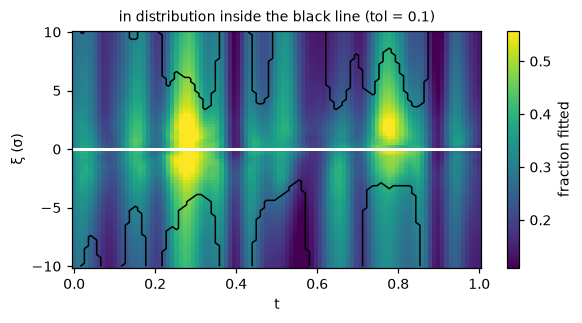

In [7]:
curve = pt.in_distribution_curve(wide, forward, tol=0.1)
plotting.ood_map(curve, wide, xlabel="t");

The curve below summarises the map, giving the fraction of columns still inside the black line at each magnitude.
`max_magnitude` then reads off the largest $|\xi|$ at which at least 95 per cent of them are, which is how far we
perturb in step 3.

in distribution up to |xi| = 3 sigma


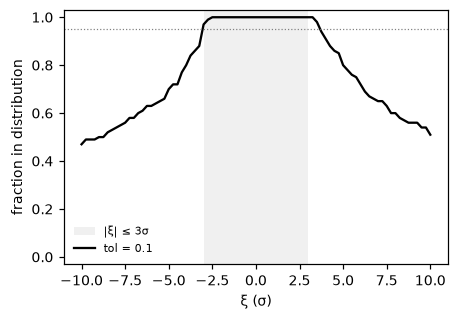

In [8]:
XI_MAX = pt.max_magnitude(curve)
print(f"in distribution up to |xi| = {XI_MAX:g} sigma")
plotting.in_distribution(curve);

Beyond $\xi_\text{max}$ the network no longer responds to a perturbation the way it does to a small one. The perturbed
signals stop looking like the noisy signals it was trained on, so its answers there tell us very little about how it
reads a real observation. This limit depends on the noise and the prior, and here, with noise comparable to the signal, it
lands at $\pm 3\sigma$.

## Step 3: perturb the sample

`Perturber(f, x_axis, sigma, fwhm)` perturbs every centre at every magnitude, here using 101 magnitudes within
$\pm\xi_\text{max}$. It returns the response $R_m = f(X'_m) - f(x^\star)$, its gradient between neighbouring
magnitudes, and the importance, which is the mean of that gradient.

In [9]:
result = pt.Perturber(f, T, SIGMA, FWHM)(x_star, pt.magnitude_grid(xi_max=XI_MAX, n=101))
print("response:", result.response.shape, "(centres, magnitudes, outputs)\nimportance:", result.importance.shape)

response: (100, 101, 8) (centres, magnitudes, outputs)
importance: (100, 8)


## Step 4: visualise

**Response-gradient maps** show, for one amplitude, a window centred at one $t$ in each column, and the slope of the
amplitude's response between two neighbouring magnitudes in each row. Purple means that raising the signal there
raises the amplitude, and orange means that it lowers it. The mean down each column is the importance. For the lowest
frequency, the colour follows its sine wave, as raising the signal where the wave is positive raises the amplitude.
The highest frequency shows the same pattern, just faster.

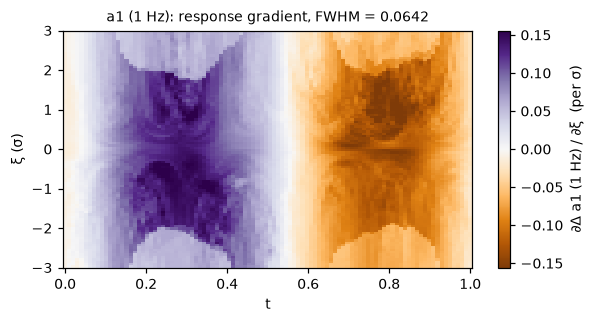

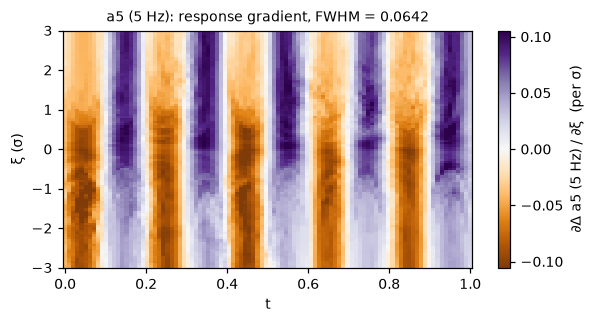

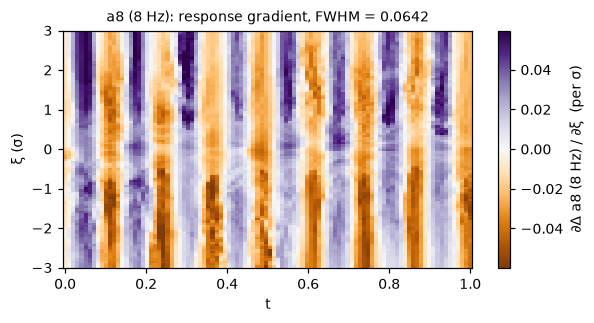

In [10]:
for p in (0, len(NAMES)//2, len(NAMES) - 1):
    plotting.gradient_map(result, output=p, names=NAMES, xlabel="t")

**Response curves** are single columns of the map, giving a ceteris paribus-style view of how the highest-frequency
amplitude moves as the window at a few positions is pushed up or down. Where that wave is large the curves are steep,
and where it is near zero they stay flat. A curve that bends shows up in the map above as a column that changes colour
partway up.

**Callouts** pick out the most interesting of these columns automatically:

- **Above the map** are the steepest columns, i.e. the two with the largest positive importance (where raising the
  signal raises the amplitude) and the two with the most negative.
- **Below the map** are the columns whose response bends furthest from a straight line, picked from the rest.

Each callout is that column's response curve, coloured by its gradient as in the map. The dashed line is the
straight-line response that the importance alone would predict, so where the two part, a single importance number
would misdescribe how the network reads that region. The picked columns are at least one kernel FWHM apart, so each
callout is a different perturbation.

`threshold` sets the largest change in the output you are willing to accept. Responses beyond $\pm$`threshold` are
blacked out on the map and shaded in the callouts, and a black line in each callout marks where its response first
crosses the threshold. This tells you how far, in units of the noise, that region of the signal has to move before the
answer changes by that much. If you have a constraint on your posterior, you can set `threshold` to it, and
backpropagate this into a limit on how noisy your observations can be while still meeting it (demo B goes through this
in detail).

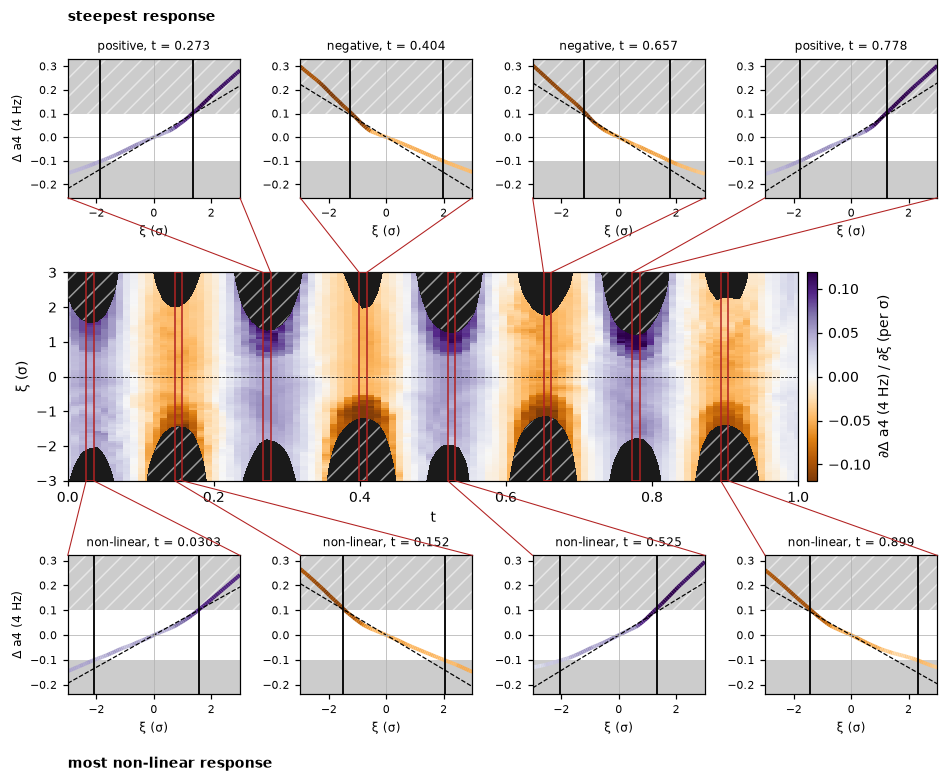

In [11]:
plotting.callouts(result, output=3, n_positive=2, n_negative=2, n_nonlinear=4, threshold=0.1,
                  names=NAMES, xlabel="t");

You can also draw a few of these columns on their own with `plotting.response_curves`.

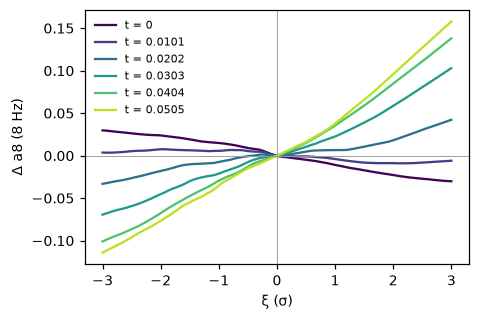

In [12]:
plotting.response_curves(result, output=len(NAMES) - 1, centres=np.arange(6), names=NAMES, xlabel="t");

Finally, the **importance** of every $t$ for every amplitude, with that amplitude's sine wave drawn faintly behind it
as a guide. Each amplitude's importance comes out as its own sine wave, which shows that the network has learned to
read each frequency from the points where that wave is largest, with the sign of the wave.

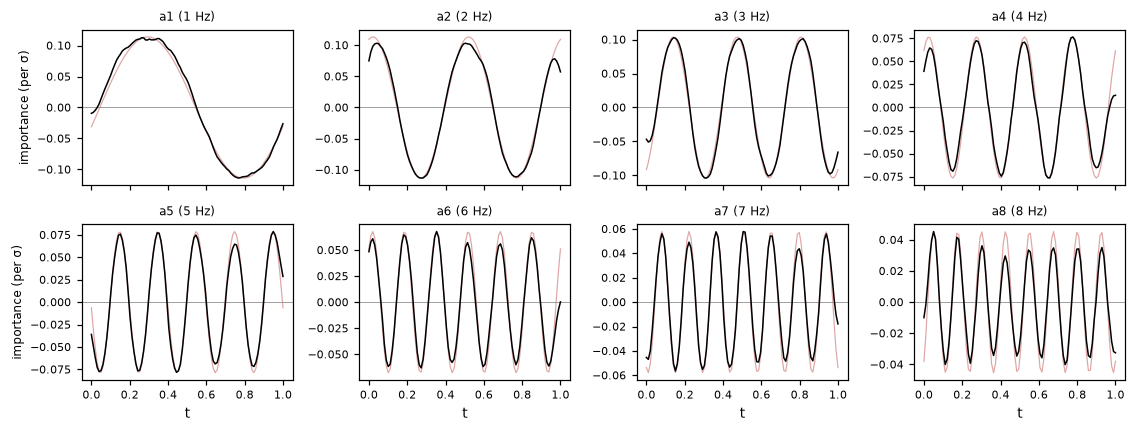

In [13]:
fig = plotting.importance(result, names=NAMES, xlabel="t")
for ax, p in zip(fig.axes, range(len(NAMES))):
    imp = result.importance[:, p]
    ax.plot(T, BASIS[p] * np.abs(imp).max(), color="firebrick", lw=0.8, alpha=0.4, zorder=0)

## Using it on your own black-box

```python
import perturb as pt
from perturb import plotting
fit = pt.fit_kernel_width(X_prior, x_axis) # 1. kernel width
wide = pt.Perturber(f, x_axis, sigma, fit["fwhm"])(x, pt.magnitude_grid(10, 81)) # explore
xi_max = pt.max_magnitude(pt.in_distribution_curve(wide, forward, tol=0.1)) # 2. set limit
result = pt.Perturber(f, x_axis, sigma, fit["fwhm"])(x, pt.magnitude_grid(xi_max)) # 3. perturb
plotting.gradient_map(result, output=0); plotting.importance(result); plotting.callouts(result) # 4. plot
```

`f` can be any function that maps an array of inputs $(N, M)$ to outputs $(N, P)$, whether that's a network, a
retrieval, or a wrapper around some external code, and `forward` maps the outputs back to inputs. Stochastic
black-boxes (e.g. ones using Monte Carlo dropout) should fix their randomness across calls, otherwise the response
maps will fill up with noise.